# Studi Kasus Webinar 3: Pemetaan Fasilitas Kesehatan di Kota Bengkulu Menggunakan GIS


## 1. Pendahuluan
GIS adalah sistem untuk mengumpulkan, mengolah, menganalisis, dan menampilkan data yang memiliki informasi lokasi. Studi kasus ini menggunakan GIS untuk mengeksplorasi persebaran fasilitas kesehatan yang tercatat di sekitar Kota Bengkulu.

## 2. Tujuan
- Mengambil data fasilitas kesehatan dari OpenStreetMap.
- Membuat peta interaktif.
- Merangkum objek berdasarkan jenis/tag.
- Menggunakan heatmap untuk eksplorasi konsentrasi titik.


## 3. Persiapan pustaka

In [1]:
!pip -q install folium pandas requests matplotlib

In [2]:
import requests
import pandas as pd
import folium
import matplotlib.pyplot as plt
from folium.plugins import MarkerCluster, HeatMap
from pathlib import Path
from IPython.display import display
print("Pustaka siap digunakan.")

Pustaka siap digunakan.


## 4. Mengambil data OpenStreetMap


In [4]:
# Bounding box perkiraan sekitar Kota Bengkulu: selatan, barat, utara, timur
south, west, north, east = -3.95, 102.20, -3.65, 102.45

overpass_url = "https://overpass-api.de/api/interpreter"

query = f'''
[out:json][timeout:60];
(
  node["amenity"~"^(hospital|clinic|doctors|dentist|pharmacy)$"]({south},{west},{north},{east});
  way["amenity"~"^(hospital|clinic|doctors|dentist|pharmacy)$"]({south},{west},{north},{east});
  relation["amenity"~"^(hospital|clinic|doctors|dentist|pharmacy)$"]({south},{west},{north},{east});

  node["healthcare"]({south},{west},{north},{east});
  way["healthcare"]({south},{west},{north},{east});
  relation["healthcare"]({south},{west},{north},{east});
);
out center tags;
'''

response = requests.post(
    overpass_url,
    data={"data": query},
    timeout=90,
    headers={"User-Agent": "Colab-GIS-Student-Case/1.0"}
)

response.raise_for_status()

elements = response.json().get("elements", [])

print("Objek diterima:", len(elements))

Objek diterima: 27


## 5. Mengolah dan membersihkan data

In [5]:
rows = []
for el in elements:
    tags = el.get("tags", {})
    if "lat" in el and "lon" in el:
        lat, lon = el["lat"], el["lon"]
    elif "center" in el:
        lat, lon = el["center"]["lat"], el["center"]["lon"]
    else:
        continue
    rows.append({
        "id_osm": f'{el.get("type", "objek")}/{el.get("id", "")}',
        "nama": tags.get("name", "Nama tidak tercantum"),
        "jenis": tags.get("amenity") or tags.get("healthcare") or "tidak diketahui",
        "latitude": float(lat), "longitude": float(lon),
        "operator": tags.get("operator", "Tidak tercantum"),
        "sumber": "OpenStreetMap"
    })
df = pd.DataFrame(rows).drop_duplicates(subset=["id_osm"])
if df.empty:
    raise ValueError("Data kosong. Coba ulangi permintaan ke Overpass API.")
df = df[df.latitude.between(south, north) & df.longitude.between(west, east)].reset_index(drop=True)
print("Jumlah objek setelah pembersihan:", len(df))
display(df.head(10))

Jumlah objek setelah pembersihan: 27


,id_osm,nama,jenis,latitude,longitude,operator,sumber
0,node/2441129247,Apotek Nita,pharmacy,-3.800996,102.273114,Tidak tercantum,OpenStreetMap
1,node/2442226309,Apotek Keluarga,pharmacy,-3.794294,102.274965,Tidak tercantum,OpenStreetMap
2,node/3130900961,dr.Lia Novita,doctors,-3.764349,102.280010,Tidak tercantum,OpenStreetMap
3,node/5343076775,Apotik Kito,pharmacy,-3.890051,102.317803,Tidak tercantum,OpenStreetMap
4,node/5363287892,Apotik Berkat,pharmacy,-3.798249,102.266863,Tidak tercantum,OpenStreetMap
5,node/5367985797,Apotik Kompas,pharmacy,-3.801414,102.264183,Tidak tercantum,OpenStreetMap
6,node/5367985799,Puskesmas,clinic,-3.808556,102.266288,Tidak tercantum,OpenStreetMap
7,node/5368048248,Apotik Kimia Farma,pharmacy,-3.798332,102.267023,Tidak tercantum,OpenStreetMap
8,node/5368109557,Puskesmas,clinic,-3.801051,102.266503,Tidak tercantum,OpenStreetMap
9,node/5368125814,Apotik Nova,pharmacy,-3.807608,102.267316,Tidak tercantum,OpenStreetMap


## 6. Ringkasan jenis fasilitas

,jenis,jumlah
3,pharmacy,10
2,hospital,8
0,clinic,7
1,doctors,2


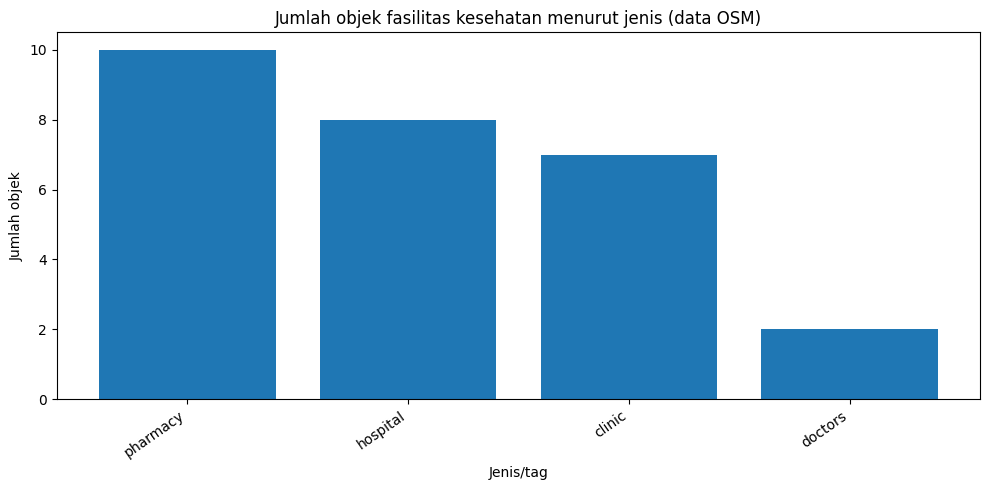

In [6]:
ringkasan = (df.groupby("jenis").size().reset_index(name="jumlah")
             .sort_values("jumlah", ascending=False))
display(ringkasan)
plt.figure(figsize=(10, 5))
plt.bar(ringkasan["jenis"], ringkasan["jumlah"])
plt.title("Jumlah objek fasilitas kesehatan menurut jenis (data OSM)")
plt.xlabel("Jenis/tag"); plt.ylabel("Jumlah objek")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

## 7. Peta interaktif dengan marker cluster

In [9]:
import folium
from folium.plugins import MarkerCluster

# Titik tengah peta
center = [df["latitude"].mean(), df["longitude"].mean()]

# Membuat peta dengan basemap Esri
peta = folium.Map(
    location=center,
    zoom_start=12,
    tiles=None
)

# Menambahkan basemap Esri WorldStreetMap
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Esri WorldStreetMap",
    overlay=False,
    control=True
).add_to(peta)

# Mengelompokkan marker fasilitas kesehatan
cluster = MarkerCluster(
    name="Fasilitas Kesehatan"
).add_to(peta)

# Menambahkan marker dari DataFrame
for _, r in df.iterrows():
    popup = (
        f"<b>{r['nama']}</b><br>"
        f"Jenis: {r['jenis']}<br>"
        f"Operator: {r['operator']}<br>"
        f"Sumber: {r['sumber']}"
    )

    folium.Marker(
        location=[r["latitude"], r["longitude"]],
        popup=folium.Popup(popup, max_width=300),
        tooltip=f"{r['nama']} — {r['jenis']}"
    ).add_to(cluster)

# Kontrol layer
folium.LayerControl().add_to(peta)

# Tampilkan peta
peta

In [10]:
# Memeriksa jumlah data fasilitas kesehatan
print("Total fasilitas kesehatan:", len(df))

# Menghitung jumlah fasilitas berdasarkan jenis
print("\nJumlah berdasarkan jenis:")
print(df["jenis"].value_counts())

# Memeriksa apakah ada koordinat kosong
print("\nKoordinat kosong:")
print(df[["latitude", "longitude"]].isnull().sum())

Total fasilitas kesehatan: 27

Jumlah berdasarkan jenis:
jenis
pharmacy    10
hospital     8
clinic       7
doctors      2
Name: count, dtype: int64

Koordinat kosong:
latitude     0
longitude    0
dtype: int64


## 8. Heatmap
Heatmap menunjukkan konsentrasi titik pada data yang terpetakan, bukan kebutuhan, kapasitas, atau kualitas layanan.

In [12]:
import folium
from folium.plugins import HeatMap

# Membuat peta panas dengan basemap Esri
peta_panas = folium.Map(
    location=center,
    zoom_start=12,
    tiles=None
)

# Menambahkan basemap Esri
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Esri WorldStreetMap",
    overlay=False,
    control=True
).add_to(peta_panas)

# Menambahkan heatmap berdasarkan koordinat fasilitas kesehatan
data_panas = df[["latitude", "longitude"]].dropna().values.tolist()

HeatMap(
    data_panas,
    radius=18,
    blur=15,
    min_opacity=0.25
).add_to(peta_panas)

# Menampilkan kontrol layer
folium.LayerControl().add_to(peta_panas)

# Menampilkan peta panas
peta_panas

## 9. Menyimpan hasil

In [13]:
out = Path("hasil_gis"); out.mkdir(exist_ok=True)
csv_path = out / "fasilitas_kesehatan_bengkulu_osm.csv"
html_path = out / "peta_fasilitas_kesehatan_bengkulu.html"
df.to_csv(csv_path, index=False); peta.save(str(html_path))
print("Tersimpan:", csv_path, "dan", html_path)
from google.colab import files
files.download(str(csv_path))
# Untuk mengunduh peta HTML juga, jalankan: files.download(str(html_path))

Tersimpan: hasil_gis/fasilitas_kesehatan_bengkulu_osm.csv dan hasil_gis/peta_fasilitas_kesehatan_bengkulu.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>